# 06. Tổng hợp và so sánh kết quả Validation

Notebook ghép kết quả đã lưu của **Dummy, Logistic Regression, Random Forest và MLP**. Trước khi so sánh, notebook đối chiếu dữ liệu, bộ chia, metadata và các bảng điểm để bảo đảm bốn mô hình được chấm theo cùng quy ước.

**Cách chạy:** chạy xong các notebook dữ liệu và bốn notebook mô hình, rồi chọn **Restart Kernel → Run All** ở notebook này. Notebook chỉ đọc các kết quả đã có; không huấn luyện lại mô hình. Phần đánh giá Test được thực hiện sau khi khóa lựa chọn trong notebook tiếp theo.

Đầu ra gồm ba bảng Validation, biểu đồ so sánh và một manifest ghi chính xác các tệp đầu vào. Manifest là bản ghi để bước đánh giá cuối dùng đúng các mô hình đã được nhóm chốt.


## 1. Xác định thư mục dự án và quy ước dùng chung

Mỗi mô hình có tên hiển thị, thư mục báo cáo, dòng cần lấy trong bảng tổng hợp và các tệp mô hình riêng. Bảng của Logistic có thêm một dòng Dummy để so sánh tại chỗ, nên phải chọn đúng một dòng Logistic khi ghép bảng toàn nhóm.

Mã băm của văn bản được tính sau khi đổi CRLF thành LF để cùng một tệp không bị coi là khác chỉ vì ký tự xuống dòng của Windows. Các tệp `.joblib` và `.pt` được băm nguyên trạng.


In [1]:
import csv
import hashlib
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Tìm thư mục gốc dù kernel đang chạy từ thư mục con của notebooks.
here = Path.cwd().resolve()
root = next((folder for folder in (here, *here.parents)
             if (folder / "common/metrics.py").is_file()
             and (folder / "data/splits/splits.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Hãy mở notebook trong thư mục dự án đã có dữ liệu và bộ chia.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.metrics import SUMMARY_COLUMNS, evaluate, per_class_frame
from common.preprocessing import FEATURE_COLUMNS, LABELS, TARGET

MODELS = [
    {"name": "Dummy", "folder": "dummy", "summary_row": "Dummy (most_frequent)",
     "metadata_path": "artifacts/dummy_pipeline.json",
     "artifact_paths": ["artifacts/dummy_pipeline.joblib"]},
    {"name": "Logistic Regression", "folder": "logistic", "summary_row": "Logistic Regression",
     "metadata_path": "artifacts/logistic_pipeline.json",
     "artifact_paths": ["artifacts/logistic_pipeline.joblib"]},
    {"name": "Random Forest", "folder": "random_forest", "summary_row": "Random Forest",
     "metadata_path": "artifacts/random_forest_pipeline.json",
     "artifact_paths": ["artifacts/random_forest_pipeline.joblib"]},
    {"name": "MLP", "folder": "mlp", "summary_row": "MLP",
     "metadata_path": "artifacts/mlp_best.json",
     "artifact_paths": ["artifacts/mlp_best.pt", "artifacts/mlp_preprocessor.joblib"]},
]
DATA_PATH = "data/raw/data.csv"
SPLIT_PATH = "data/splits/splits.json"
TABLE_FILES = ("validation_summary.csv", "validation_per_class.csv", "validation_confusion.csv")


def input_hash(relative_path):
    # Tệp mô hình là nhị phân; dữ liệu, mã nguồn, JSON và CSV dùng xuống dòng LF.
    path = root / relative_path
    content = path.read_bytes()
    if path.suffix.lower() not in {".joblib", ".pt"}:
        content = content.replace(b"\r\n", b"\n")
    return hashlib.sha256(content).hexdigest()


input_paths = [DATA_PATH, SPLIT_PATH, "common/metrics.py", "common/preprocessing.py"]
for spec in MODELS:
    input_paths.extend([spec["metadata_path"], *spec["artifact_paths"]])
    input_paths.extend(f"reports/tables/{spec['folder']}/{name}" for name in TABLE_FILES)
if len(input_paths) != len(set(input_paths)):
    raise ValueError("Danh sách đầu vào bị lặp đường dẫn.")
missing_files = [name for name in input_paths if not (root / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Thiếu tệp bàn giao: {missing_files}")
input_sha256 = {name: input_hash(name) for name in input_paths}
print(f"Đã tìm thấy đủ {len(MODELS)} mô hình và {len(input_paths)} tệp đầu vào.")


Đã tìm thấy đủ 4 mô hình và 25 tệp đầu vào.


## 2. Kiểm tra bộ chia và nhãn Validation

Bộ chia phải gồm các chỉ số nguyên hợp lệ, không lặp, không giao nhau và bao phủ đủ CSV gốc. Notebook chỉ giữ nhãn của các dòng thuộc Validation để đối chiếu số mẫu từng lớp; không dùng nhãn Train hoặc Test để phân tích kết quả.

Danh sách đặc trưng vẫn lấy từ `common/preprocessing.py`, còn nhãn luôn theo thứ tự `Dropout → Enrolled → Graduate`.


In [2]:
split = json.loads((root / SPLIT_PATH).read_text(encoding="utf-8"))
if split["sha256"] != input_sha256[DATA_PATH]:
    raise ValueError("CSV không khớp với dữ liệu đã tạo bộ chia chung.")
if type(split["n_rows"]) is not int or split["n_rows"] <= 0:
    raise ValueError("Số dòng trong bộ chia không hợp lệ.")
if type(split["seed"]) is not int:
    raise ValueError("Seed trong bộ chia phải là số nguyên.")
if len(FEATURE_COLUMNS) != len(set(FEATURE_COLUMNS)) or len(LABELS) != len(set(LABELS)):
    raise ValueError("Danh sách đặc trưng hoặc nhãn dùng chung bị lặp.")


def checked_rows(name):
    rows = split[name]
    if not isinstance(rows, list) or not rows:
        raise ValueError(f"Tập {name} phải là danh sách chỉ số dòng và không được rỗng.")
    if any(type(row) is not int or not 0 <= row < split["n_rows"] for row in rows):
        raise ValueError(f"Tập {name} chứa chỉ số dòng không hợp lệ.")
    if len(rows) != len(set(rows)):
        raise ValueError(f"Tập {name} chứa chỉ số dòng bị lặp.")
    return rows


train_rows = checked_rows("train")
validation_rows = checked_rows("validation")
test_rows = checked_rows("test")
all_rows = train_rows + validation_rows + test_rows
if len(all_rows) != len(set(all_rows)) or set(all_rows) != set(range(split["n_rows"])):
    raise ValueError("Ba tập phải tách biệt và bao gồm đầy đủ mọi dòng CSV.")

# Duyệt CSV để đếm dòng; chỉ lấy giá trị nhãn ở những dòng Validation đã lưu.
validation_row_set = set(validation_rows)
validation_labels_by_row = {}
with (root / DATA_PATH).open(encoding="utf-8-sig", newline="") as stream:
    reader = csv.reader(stream, delimiter=";")
    columns = [name.strip() for name in next(reader)]
    if len(columns) != len(set(columns)) or set(columns) != set(FEATURE_COLUMNS) | {TARGET}:
        raise ValueError("Các cột CSV không khớp với danh sách đặc trưng và Target dùng chung.")
    target_position = columns.index(TARGET)
    n_rows = 0
    for row_index, row in enumerate(reader):
        if len(row) != len(columns):
            raise ValueError(f"Dòng CSV số {row_index} không có đủ số cột.")
        n_rows += 1
        if row_index in validation_row_set:
            validation_labels_by_row[row_index] = row[target_position]
if n_rows != split["n_rows"]:
    raise ValueError("Số dòng CSV không khớp với bộ chia.")
y_validation = pd.Series(
    [validation_labels_by_row[row] for row in validation_rows], name=TARGET,
)
if not y_validation.isin(LABELS).all():
    raise ValueError("Validation chứa nhãn lạ hoặc nhãn bị thiếu.")
validation_support = y_validation.value_counts().reindex(LABELS, fill_value=0)
print(f"Train: {len(train_rows):,}; Validation: {len(validation_rows):,}; Test: {len(test_rows):,} dòng.")
display(validation_support.rename("support").to_frame())


Train: 3,096; Validation: 664; Test: 664 dòng.


,support
Target,
Dropout,213
Enrolled,119
Graduate,332


## 3. Đối chiếu metadata và kiểm tra lại các bảng điểm

Với từng mô hình, notebook kiểm tra hash dữ liệu, seed, thứ tự nhãn và số đặc trưng gốc. Metadata mới có hash bộ chia thì được kiểm tra thêm; metadata cũ chưa có trường này vẫn phải khớp các thông tin còn lại.

Từ ma trận nhầm lẫn đã lưu, notebook dựng lại các cặp nhãn thật–nhãn dự đoán theo số đếm rồi gọi **hàm `evaluate()` dùng chung**. Cách này kiểm tra được tính nhất quán của bảng tổng hợp và chỉ số từng lớp. Nó không xác minh dự đoán theo từng sinh viên; bước nạp lại mô hình ở notebook đánh giá cuối sẽ kiểm tra điều đó.


In [3]:
def require_close(actual, expected, description):
    # Sai số nhỏ cho phép CSV và JSON lưu số thực với số chữ số hơi khác nhau.
    actual = np.asarray(actual, dtype=float)
    expected = np.asarray(expected, dtype=float)
    if actual.shape != expected.shape or not np.isfinite(actual).all() or not np.isfinite(expected).all():
        raise ValueError(f"{description}: dữ liệu số không hợp lệ hoặc sai kích thước.")
    if not np.allclose(actual, expected, rtol=1e-10, atol=1e-12):
        raise ValueError(f"{description}: các kết quả không khớp nhau.")


summary_rows = []
per_class_tables = []
confusion_tables = []
verified_results = {}
for spec in MODELS:
    name = spec["name"]
    metadata = json.loads((root / spec["metadata_path"]).read_text(encoding="utf-8"))
    if metadata["data_sha256"] != input_sha256[DATA_PATH] or metadata["split_seed"] != split["seed"]:
        raise ValueError(f"{name}: dữ liệu hoặc seed không khớp bộ chia chung.")
    if list(metadata["labels"]) != list(LABELS) or metadata["n_features_in"] != len(FEATURE_COLUMNS):
        raise ValueError(f"{name}: thứ tự nhãn hoặc số đặc trưng đầu vào không khớp.")
    if "feature_columns" in metadata and list(metadata["feature_columns"]) != list(FEATURE_COLUMNS):
        raise ValueError(f"{name}: danh sách đặc trưng không khớp.")
    if "split_file_sha256" in metadata and metadata["split_file_sha256"] != input_sha256[SPLIT_PATH]:
        raise ValueError(f"{name}: hash bộ chia không khớp.")
    for key, expected in (("n_train", len(train_rows)), ("n_validation", len(validation_rows)),
                          ("validation_n_samples", len(validation_rows))):
        if key in metadata and metadata[key] != expected:
            raise ValueError(f"{name}: {key} không khớp bộ chia.")

    table_dir = root / "reports/tables" / spec["folder"]
    saved_summary = pd.read_csv(table_dir / "validation_summary.csv", index_col=0)
    # Chọn chính xác một dòng, đặc biệt bảng Logistic còn có dòng Dummy tham chiếu.
    if int((saved_summary.index == spec["summary_row"]).sum()) != 1:
        raise ValueError(f"{name}: bảng tổng hợp phải có đúng một dòng cần lấy.")
    if not set(SUMMARY_COLUMNS).issubset(saved_summary.columns):
        raise ValueError(f"{name}: bảng tổng hợp thiếu metric dùng chung.")
    saved_row = saved_summary.loc[spec["summary_row"], list(SUMMARY_COLUMNS)].astype(float)

    saved_per_class = pd.read_csv(table_dir / "validation_per_class.csv", index_col=0)
    saved_confusion = pd.read_csv(table_dir / "validation_confusion.csv", index_col=0)
    if list(saved_per_class.index) != list(LABELS):
        raise ValueError(f"{name}: thứ tự lớp trong bảng từng lớp không đúng.")
    if list(saved_confusion.index) != list(LABELS) or list(saved_confusion.columns) != list(LABELS):
        raise ValueError(f"{name}: thứ tự lớp trong ma trận nhầm lẫn không đúng.")
    counts = saved_confusion.to_numpy(dtype=float)
    if not np.isfinite(counts).all() or (counts < 0).any() or not np.equal(counts, np.floor(counts)).all():
        raise ValueError(f"{name}: ma trận nhầm lẫn phải chứa số đếm nguyên không âm.")
    counts = counts.astype(np.int64)
    require_close(counts.sum(axis=1), validation_support.to_numpy(), f"{name}: support Validation")

    # Mỗi ô (i, j) tương ứng counts[i, j] mẫu thật lớp i và được đoán lớp j.
    true_positions, predicted_positions = np.indices(counts.shape)
    label_array = np.asarray(LABELS, dtype=object)
    reconstructed_true = np.repeat(label_array[true_positions.ravel()], counts.ravel())
    reconstructed_pred = np.repeat(label_array[predicted_positions.ravel()], counts.ravel())
    result = evaluate(reconstructed_true, reconstructed_pred)
    verified_results[name] = result
    reconstructed_summary = [result[column] for column in SUMMARY_COLUMNS]
    require_close(saved_row.to_numpy(), reconstructed_summary, f"{name}: bảng tổng hợp")
    metadata_scores = metadata["validation_metrics"] if name == "Dummy" else metadata["validation"]
    require_close([metadata_scores[column] for column in SUMMARY_COLUMNS], reconstructed_summary,
                  f"{name}: metric trong metadata")
    expected_per_class = per_class_frame(result)
    if not set(expected_per_class.columns).issubset(saved_per_class.columns):
        raise ValueError(f"{name}: bảng từng lớp thiếu cột metric.")
    saved_per_class = saved_per_class.loc[list(LABELS), expected_per_class.columns].astype(float)
    require_close(saved_per_class.to_numpy(), expected_per_class.to_numpy(), f"{name}: metric từng lớp")
    saved_per_class["support"] = saved_per_class["support"].astype(int)

    summary_rows.append({"model": name, **{column: float(saved_row[column]) for column in SUMMARY_COLUMNS}})
    per_class_output = saved_per_class.rename_axis("label").reset_index()
    per_class_output.insert(0, "model", name)
    per_class_tables.append(per_class_output)
    confusion_output = pd.DataFrame(counts, index=LABELS, columns=LABELS).rename_axis("true_label").reset_index()
    confusion_output.insert(0, "model", name)
    confusion_tables.append(confusion_output)
    print(f"{name}: metadata và ba bảng Validation khớp nhau.")

validation_summary = pd.DataFrame(summary_rows).set_index("model").loc[:, list(SUMMARY_COLUMNS)]
validation_per_class = pd.concat(per_class_tables, ignore_index=True)
validation_confusion = pd.concat(confusion_tables, ignore_index=True)
if (len(validation_summary), len(validation_per_class), len(validation_confusion)) != (4, 12, 12):
    raise ValueError("Số dòng sau khi ghép không đúng: cần 4 dòng tổng hợp và 12 dòng cho mỗi bảng chi tiết.")
selected_model = str(validation_summary["macro_f1"].idxmax())
display(validation_summary.sort_values("macro_f1", ascending=False, kind="stable"))
display(validation_per_class)
print(f"Mô hình được chọn theo Macro-F1 Validation: {selected_model}.")


Dummy: metadata và ba bảng Validation khớp nhau.
Logistic Regression: metadata và ba bảng Validation khớp nhau.
Random Forest: metadata và ba bảng Validation khớp nhau.


MLP: metadata và ba bảng Validation khớp nhau.


,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
Random Forest,0.777108,0.729291,0.751174,0.816327,0.763359
Logistic Regression,0.731928,0.693800,0.741784,0.802030,0.753098
MLP,0.710843,0.683275,0.699531,0.805405,0.718419
Dummy,0.500000,0.222222,0.000000,0.000000,0.000000


,model,label,precision,recall,f1,f2,support
0,Dummy,Dropout,0.000000,0.000000,0.000000,0.000000,213
1,Dummy,Enrolled,0.000000,0.000000,0.000000,0.000000,119
2,Dummy,Graduate,0.500000,1.000000,0.666667,0.833333,332
3,Logistic Regression,Dropout,0.802030,0.741784,0.770732,0.753098,213
4,Logistic Regression,Enrolled,0.413793,0.605042,0.491468,0.553846,119
5,Logistic Regression,Graduate,0.873720,0.771084,0.819200,0.789636,332
6,Random Forest,Dropout,0.816327,0.751174,0.782396,0.763359,213
7,Random Forest,Enrolled,0.536000,0.563025,0.549180,0.557404,119
8,Random Forest,Graduate,0.842566,0.870482,0.856296,0.864752,332
9,MLP,Dropout,0.805405,0.699531,0.748744,0.718419,213


Mô hình được chọn theo Macro-F1 Validation: Random Forest.


## 4. Biểu đồ và nhận xét

Ở bộ kết quả đang bàn giao, **Random Forest** có Macro-F1 Validation cao nhất (**0.7293**), tiếp theo là Logistic Regression (**0.6938**) và MLP (**0.6833**). Dummy đạt **0.2222**. Đây là căn cứ chọn Random Forest trước khi đánh giá cuối trên Test.

- Dummy đạt accuracy **0.5000** do luôn chọn `Graduate`, nhưng recall `Dropout` bằng **0**. Vì vậy, accuracy riêng lẻ chưa phản ánh khả năng nhận diện sinh viên bỏ học.
- Random Forest có recall `Dropout` khoảng **0.7512**, Logistic **0.7418** và MLP **0.6995**. Điểm số cho thấy các mô hình vẫn bỏ sót một phần sinh viên thuộc lớp này.
- MLP hiện tại chọn cấu hình và số epoch trong phần nội bộ của Train, sau đó fit lại toàn bộ Train và chấm Validation chung. Điểm **0.6833** là kết quả của quy trình đó.

Các khác biệt ở trên là kết quả trên một bộ chia cố định; chưa đủ để khẳng định mô hình nào luôn tốt hơn trong mọi bối cảnh. Tầm quan trọng đặc trưng cũng phản ánh cách mô hình dự đoán, không chứng minh nguyên nhân gây bỏ học.


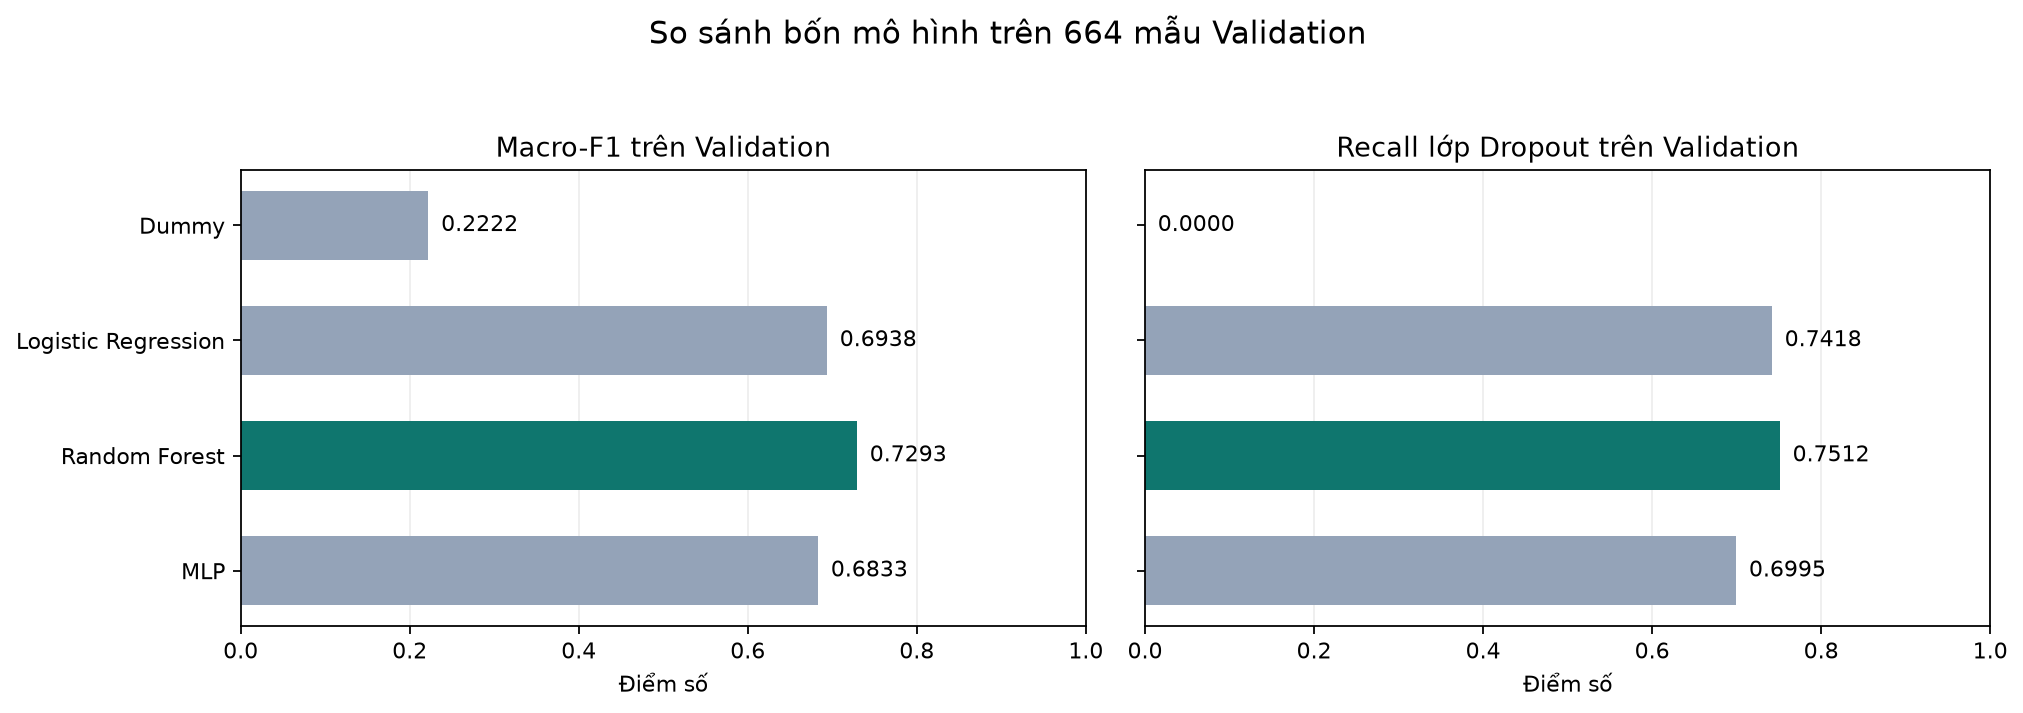

In [4]:
figure_dir = root / "reports/figures/comparison"
figure_dir.mkdir(parents=True, exist_ok=True)
model_names = list(validation_summary.index)
colors = ["#0f766e" if name == selected_model else "#94a3b8" for name in model_names]
figure, axes = plt.subplots(1, 2, figsize=(12.8, 4.5), sharey=True)
for axis, metric, title in zip(
    axes, ("macro_f1", "dropout_recall"),
    ("Macro-F1 trên Validation", "Recall lớp Dropout trên Validation"),
):
    values = validation_summary[metric].to_numpy()
    axis.barh(model_names, values, color=colors, height=0.6)
    axis.set_xlim(0, 1)
    axis.set_xlabel("Điểm số")
    axis.set_title(title)
    axis.grid(axis="x", alpha=0.22)
    axis.set_axisbelow(True)
    for position, value in enumerate(values):
        axis.text(value + 0.015, position, f"{value:.4f}", va="center", fontsize=10)
axes[0].invert_yaxis()
figure.suptitle(f"So sánh bốn mô hình trên {len(validation_rows):,} mẫu Validation", fontsize=14)
figure.tight_layout(rect=(0, 0, 1, 0.93))
figure_path = figure_dir / "validation_comparison.png"
figure.savefig(figure_path, dpi=160, facecolor="white", bbox_inches="tight")
plt.close(figure)
from IPython.display import Image
display(Image(filename=str(figure_path)))


## 5. Lưu bảng so sánh và khóa danh sách đầu vào

Manifest lưu hash của CSV, bộ chia, mã tiền xử lý, mã metric, chín tệp mô hình/metadata và mười hai bảng Validation nguồn. Trước khi ghi, notebook kiểm tra lại để tránh chốt một tập đầu vào đã thay đổi giữa lúc chạy.

**Bàn giao:** `validation_summary.csv` có bốn dòng mô hình; `validation_per_class.csv` và `validation_confusion.csv` đều có mười hai dòng. `validation_manifest.json` lưu mô hình được chọn theo Macro-F1 cùng đúng danh sách mô hình sẽ dùng ở bước đánh giá cuối. Các tệp mô hình gốc được giữ nguyên.


In [5]:
# Nếu thành viên khác vừa ghi lại mô hình hoặc báo cáo, cần chạy lại từ đầu trước khi khóa.
changed_inputs = [name for name, checksum in input_sha256.items() if input_hash(name) != checksum]
if changed_inputs:
    raise ValueError(f"Đầu vào đã thay đổi trong lúc chạy; hãy chạy lại notebook: {changed_inputs}")

table_dir = root / "reports/tables/comparison"
table_dir.mkdir(parents=True, exist_ok=True)
validation_summary.to_csv(table_dir / "validation_summary.csv")
validation_per_class.to_csv(table_dir / "validation_per_class.csv", index=False)
validation_confusion.to_csv(table_dir / "validation_confusion.csv", index=False)

manifest = {
    "dataset": {"path": DATA_PATH, "sha256_lf": input_sha256[DATA_PATH], "n_rows": n_rows},
    "split": {
        "path": SPLIT_PATH, "sha256_lf": input_sha256[SPLIT_PATH], "seed": split["seed"],
        "n_train": len(train_rows), "n_validation": len(validation_rows), "n_test": len(test_rows),
    },
    "labels": list(LABELS),
    "feature_columns": list(FEATURE_COLUMNS),
    "models": MODELS,
    "input_sha256": input_sha256,
    "hash_mode": "binary_for_models_lf_for_text",
    "selected_model": selected_model,
    "selection_metric": "macro_f1",
    "validation": {
        name: {column: float(validation_summary.loc[name, column]) for column in SUMMARY_COLUMNS}
        for name in validation_summary.index
    },
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
}
manifest_path = table_dir / "validation_manifest.json"
manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Đã lưu:")
for filename in ("validation_summary.csv", "validation_per_class.csv", "validation_confusion.csv", "validation_manifest.json"):
    print(f"- {(table_dir / filename).relative_to(root)}")
print(f"- {figure_path.relative_to(root)}")
print(f"Đã khóa {selected_model} theo Macro-F1 Validation; chuyển sang notebook đánh giá Test.")


Đã lưu:
- reports\tables\comparison\validation_summary.csv
- reports\tables\comparison\validation_per_class.csv
- reports\tables\comparison\validation_confusion.csv
- reports\tables\comparison\validation_manifest.json
- reports\figures\comparison\validation_comparison.png
Đã khóa Random Forest theo Macro-F1 Validation; chuyển sang notebook đánh giá Test.
